In [1]:
import numpy as np
import tensorflow as tf
from tensorflow import keras

# Load dataset
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

# Verification of shapes and data types
print("=== Train-Test Split Verification ===")
print(f"Training Images Shape : {x_train.shape} (Type: {x_train.dtype})")
print(f"Training Labels Shape : {y_train.shape} (Type: {y_train.dtype})")
print(f"Test Images Shape     : {x_test.shape} (Type: {x_test.dtype})")
print(f"Test Labels Shape     : {y_test.shape} (Type: {y_test.dtype})")

# Pixel value inspection before normalization
print(f"\nRaw Pixel Range       : Min = {x_train.min()}, Max = {x_train.max()}")
print(f"Total Samples         : {len(x_train) + len(x_test)} ({len(x_train)} train / {len(x_test)} test)")

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
=== Train-Test Split Verification ===
Training Images Shape : (60000, 28, 28) (Type: uint8)
Training Labels Shape : (60000,) (Type: uint8)
Test Images Shape     : (10000, 28, 28) (Type: uint8)
Test Labels Shape     : (10000,) (Type: uint8)

Raw Pixel Range       : Min = 0, Max = 255
Total Samples         : 70000 (60000 train / 10000 test)


In [2]:
# Normalize pixel values
x_train_norm = x_train.astype("float32") / 255.0
x_test_norm = x_test.astype("float32") / 255.0

# Add channel dimension (28, 28) -> (28, 28, 1)
x_train_norm = np.expand_dims(x_train_norm, axis=-1)
x_test_norm = np.expand_dims(x_test_norm, axis=-1)

print("=== Post-Preprocessing Shapes & Ranges ===")
print(f"Normalized Train Shape : {x_train_norm.shape}")
print(f"Normalized Test Shape  : {x_test_norm.shape}")
print(f"Normalized Pixel Range : Min = {x_train_norm.min():.1f}, Max = {x_train_norm.max():.1f}")

=== Post-Preprocessing Shapes & Ranges ===
Normalized Train Shape : (60000, 28, 28, 1)
Normalized Test Shape  : (10000, 28, 28, 1)
Normalized Pixel Range : Min = 0.0, Max = 1.0


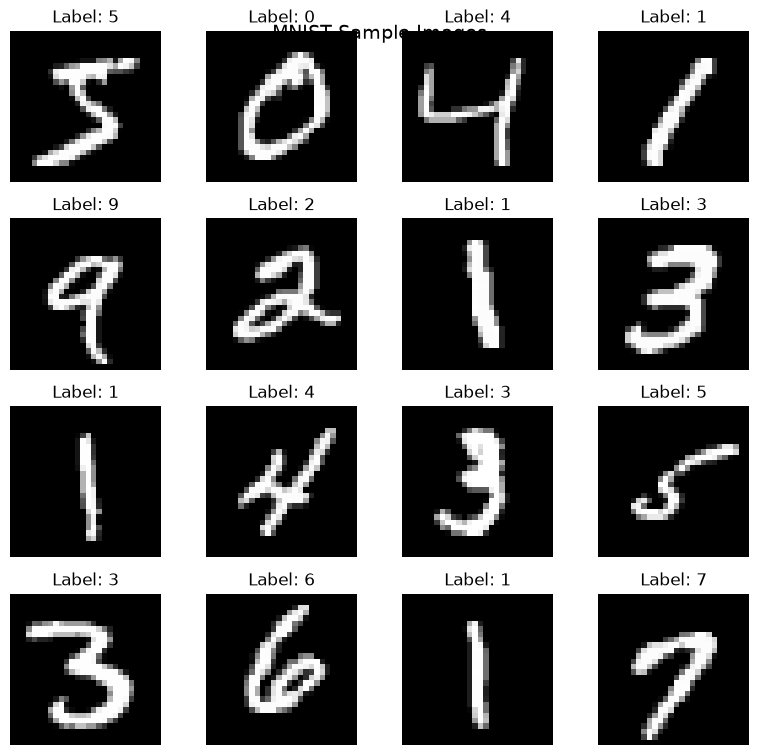

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 8))
for i in range(16):
    plt.subplot(4, 4, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')

plt.suptitle("MNIST Sample Images", fontsize=14, y=0.92)
plt.tight_layout()
plt.show()

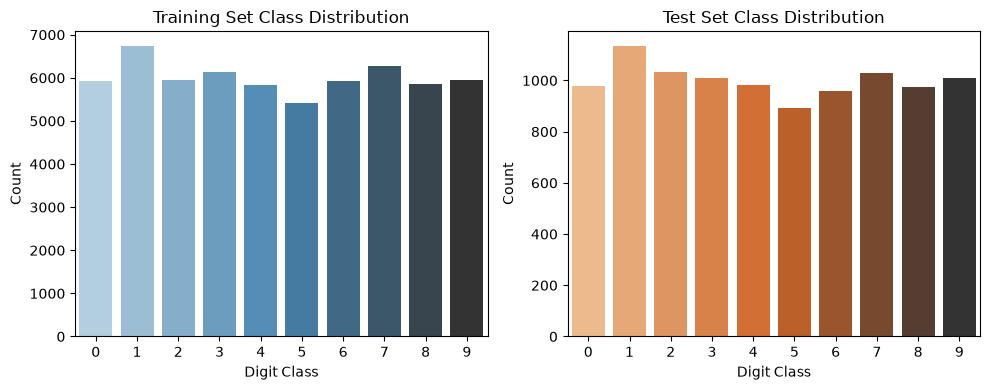

In [4]:
import seaborn as sns

train_counts = np.bincount(y_train)
test_counts = np.bincount(y_test)
digits = np.arange(10)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
sns.barplot(x=digits, y=train_counts, palette="Blues_d", hue=digits, legend=False)
plt.title("Training Set Class Distribution")
plt.xlabel("Digit Class")
plt.ylabel("Count")
plt.xticks(digits)

plt.subplot(1, 2, 2)
sns.barplot(x=digits, y=test_counts, palette="Oranges_d", hue=digits, legend=False)
plt.title("Test Set Class Distribution")
plt.xlabel("Digit Class")
plt.ylabel("Count")
plt.xticks(digits)

plt.tight_layout()
plt.show()